# Desenvolvimento do modelo de Multi Layer Perceptron (MLP) Classifier Binário de duas camadas ocultas
---

***A Fazeres:***
- Buscar `GridSearch`
- Buscar `Ensamble`
- Buscar `LaTeX`
- Buscar `overleaf.com`

Esse notebook mostra o desenvolvimento, de maneira explicada, de um `MLP` de duas camadas. Trará aplicações de `RFE`, limiares relativos à `Sensibilidade`, `Precisão` e `Equilíbrio`.

Serão teinados quatro modelos com arquitetura em funil:
- `Categoria 1`:
    1. O primeiro terá arquitetura em **funil decrescente**: a primeira camada oculta é a maior e, após ela, será divido o valor de neurônios pela metade) **SEM** a aplicação do `RFE`;
    2. O segundo terá arquitetura em **funil crescente**: a primeira camada oculta é a menor e, após ela, será multiplicado por 2 o valor de neurônios, **SEM** a aplicação do `RFE`;
- `Categoria 2`:
    1. O terceiro será como o primeiro (decrescente), mas **COM** a aplicação do `RFE`;
    2. O quarto será como o segundo (crescente), mas **COM** a aplicação do `RFE`;

Será usado `GridSearchCV` para eleger um modelo campeão de cada uma das categorias. Ao final, os campeões terão suas características analisadas

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_selection import RFE
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [115]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [116]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [117]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [118]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')
# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [119]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')
# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento dos Modelos de MLP de Classificação de duas camadas sem a aplicação do RFE
---

### 1. Aplicação do PredefinedSplit usando X_treino
---

In [8]:
limite = int(len(X_treino) * 0.8)

# -1 indica dados de treino | 0 indica dados de validação
indices_validacao = np.zeros(X_treino.shape[0])
indices_validacao[:limite] = -1  # Treino
indices_validacao[limite:] = 0   # Validação

# Divisor customizado
pds = PredefinedSplit(test_fold=indices_validacao)

### 2. Criação do modelo base
---

In [9]:
# Grid Search passando o 'pds' no lugar do 'cv'(Cross-Validation)
mlp_base = MLPClassifier(
    max_iter=2000, tol=0.0001, learning_rate_init=0.001, 
    learning_rate='adaptive', alpha=0.001, n_iter_no_change=15, 
    solver="adam", activation='relu', random_state=42
)

#### 2.1. Explicação dos hiperparâmetros
---

- `hidden_layer_sizes=(64,32)`: quantidade de camadas ocultas e quantos neurônios há em cada uma. No caso, a rede possui duas camadas ocultas: a primeira com 64 neurônios e a segunda com 32.
- `max_iter=2000`: limite máximo de iterações de treinamento. Se chegar a 2000 voltas, o treinamento para obrigatoriamente, mesmo que não tenha atingido a perfeição.
- `tol=0.0001`: tolerância para melhoria do erro (loss). Se a diferença de erro entre uma iteração e outra for menor do que 0.0001, o Python entende que a rede estabilizou e parou de evoluir significativamente.
- `learning_rate_init=0.001`: taxa de aprendizado inicial (tamanho do passo). Define o quão grandes serão os passos que o otimizador dará para ajustar os pesos. Passos muito grandes (0.1) podem fazer a rede neural ignorar a solução ideal; passos muito pequenos (0.00001) fazem o treinamento demorar muito mais. O 0.001 é um bom meio-termo, trazendo eficiência e um menor tempo de aprendizagem. A fórmula utilizada pelo modelo do Scikit-Learn é a `Gradiente Descendente`: $$w_{novo} = w_{antigo} - \eta \cdot \frac{\partial Loss}{\partial w}$$
- `learning_rate='adaptive'`: comportamento da taxa de aprendizado ao longo do tempo. Enquanto o modelo estiver conseguindo diminuir o erro, ele mantém o passo inicial (0.001). Se o erro parar de cair por duas épocas seguidas, a rede divide a taxa de aprendizado por 5, dando passos menores e mais cautelosos para tentar melhorar.
- `validation_fraction=0.1`: Reserva 10% dos seus dados de treino para usar como validação. A rede treina nos outros 90% e se testa nesses 10% para saber se está realmente aprendendo ou apenas decorando. É com base nessa nota que o `n_iter_no_change` e o `learning_rate='adaptive'` tomam suas decisões.
- `alpha=0.001`: evita o `overfitting` (regularização L2). Penaliza pesos que fiquem grandes demais na rede. Isso força o modelo a se manter simples e impede que ele decore o banco de dados de treino, ajudando-o a funcionar bem com dados novos de verdade. A fórmula de Regularização L2 (ou Ridge) é: $$Loss_{total} = Loss_{original} + \alpha \sum_{i} w_i^2$$
- `n_iter_no_change=15`: número de iterações que a rede vai esperar se a melhora do erro ficar abaixo daquela tolerância (tol). Se por 15 vezes seguidas o modelo não melhorar quase nada, ele aciona o "early stopping" (parada precoce) e encerra o treino para economizar tempo.
- `solver="adam"`: motor matemático que ajusta os pesos da rede otimizando-a. O `adam` é o algoritmo padrão do mercado. Funciona como um piloto automático inteligente que descobre sozinho o melhor caminho para diminuir os erros do modelo de forma rápida e eficiente. A fórmula simplificada de como o adam ajusta o passo a cada iteração $t$ é:$$w_t = w_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$
- `activation='relu'`: função de ativação dos neurônios. Decide se o neurônio deve ser ativado ou não. `A ReLU` (Rectified Linear Unit) pega qualquer número negativo e transforma em zero, e mantém os números positivos como estão. É a mais usada porque ajuda a rede a aprender padrões complexos rapidamente sem travar o código. Sua fórmula é:

  $f(x) = \max(0, x)$
- `verbose=True`: exibe na tela do terminal o progresso do erro a cada iteração que passa. Essencial para acompanhar se o modelo está evoluindo ou se travou.
- `random_state=42`: semente de aleatoriedade. Redes neurais começam com pesos aleatórios e embaralham os dados antes de treinar. Definir o número 42 (ou qualquer outro número fixo) garante que a aleatoriedade seja exatamente a mesma toda vez que  rodar o script. Assim, os resultados serão iguais e replicáveis.

### 3. Definição dos parâmetros e instanciação da classe GridSearchCV 
---

In [10]:
parametros = {'hidden_layer_sizes': [(64, 32), (32, 64)]}

#### 3.1. Explicação dos hiperparâmetros
---

In [11]:
# cv=pds vai rodar apenas uma vez cada arquitetura
grid_search = GridSearchCV(estimator=mlp_base, param_grid=parametros, cv=pds, n_jobs=4, verbose=2)

- `estimator=mlp_base`: define o algoritmo base que será testado. No caso, indica que o Grid Search aplicará as combinações de parâmetros em cima da estrutura da Rede Neural Multi-Layer Perceptron (MLPClassifier).
- `param_grid=parametros`: o dicionário de busca que contém a grade de opções. Se o dicionário testar, por exemplo, 3 arquiteturas de camadas ocultas e 3 taxas de aprendizado diferentes, o Grid Search multiplicará essas opções para testar de forma exaustiva todas as $3 \times 3 = 9$ combinações possíveis.
- `cv=pds`: estratégia de validação cruzada (Cross-Validation). O pds (objeto PredefinedSplit) indica que os conjuntos de dados de treino e teste/validação já possuem uma divisão fixa pré-definida. Isso faz com que cada arquitetura seja executada apenas uma vez em vez de rodar o padrão de 5 vezes (5-fold), economizando tempo de processamento e respeitando a divisão original do dataset UNSW-NB15.
- `n_jobs=4`: define o nível de paralelismo do processo de busca. Ao configurar o valor como 4, o Python instrui o processador a abrir 4 núcleos de processamento (threads) em paralelo. Isso permite que o computador treine até 4 redes neurais de uma só vez, reduzindo o tempo total do Grid Search em quase $4\times$

### 4. Treino dos modelos com GridSearchCV 
---

In [12]:
pm.imprimir_desempenho(grid_search.fit, X_treino, y_treino)

Fitting 1 folds for each of 2 candidates, totalling 2 fits

RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 09:41:50

    1. TEMPO: 966.6675s (16.11 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 16.92 MB
        - Diferença líquida de RAM no processo: -20.33 MB
        - Total RAM alocada para o processo: 344.68 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 22.0%

  Execução concluída em: 29/05/2026 09:57:56



GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0], shape=(96822,))),
             estimator=MLPClassifier(alpha=0.001, learning_rate='adaptive',
                                     max_iter=2000, n_iter_no_change=15,
                                     random_state=42),
             n_jobs=4, param_grid={'hidden_layer_sizes': [(64, 32), (32, 64)]},
             verbose=2)

### 5. Resultado e escolha do modelo campeão
---

In [13]:
print("\nResultado:")
print(f" - Melhor arquitetura encontrada: {grid_search.best_params_['hidden_layer_sizes']}")
print(f" - Acurácia na validação fixa: {grid_search.best_score_:.4f}")


Resultado:
 - Melhor arquitetura encontrada: (64, 32)
 - Acurácia na validação fixa: 0.8958


In [14]:
modelo_campeao = grid_search.best_estimator_

### 6. Realização das Predições de Teste
---

#### 6.1. Predição Probababilística
---

Para a Predição Probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo_campeao.predict_proba(X_teste)`

In [15]:
y_predicao_probabilistica_1 = pm.imprimir_desempenho(modelo_campeao.predict_proba, X_teste)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 09:57:56

    1. TEMPO: 0.2268s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 54.52 MB
        - Diferença líquida de RAM no processo: 26.85 MB
        - Total RAM alocada para o processo: 371.59 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 67.6%

  Execução concluída em: 29/05/2026 09:57:57



#### 6.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo_campeao.predict(X_teste)`

In [16]:
y_predicao_binaria_1 = pm.imprimir_desempenho(modelo_campeao.predict, X_teste)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 09:57:57

    1. TEMPO: 0.2279s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 54.52 MB
        - Diferença líquida de RAM no processo: 0.00 MB
        - Total RAM alocada para o processo: 371.60 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 61.9%

  Execução concluída em: 29/05/2026 09:57:57



### 7. Desempenho do modelo
---

#### 7.1. Limiar Padrão (0.5)
---

##### 7.1.1. Matriz de Confusão
---

<Axes: >

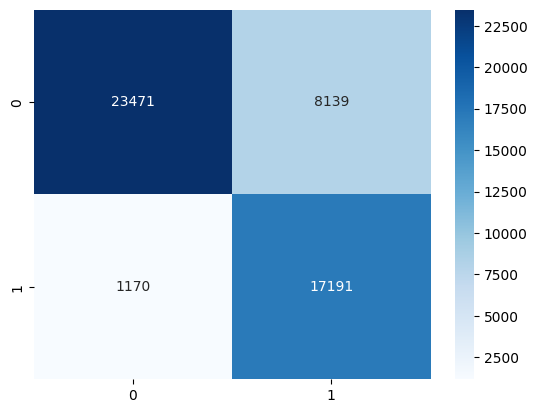

In [17]:
matriz_confusao_1 = confusion_matrix(y_teste, y_predicao_binaria_1)
sns.heatmap(matriz_confusao_1, annot=True, fmt='d', cmap='Blues')

##### 7.1.2. Relatório de Classificação
---

In [18]:
relatorio_classificacao_1 = classification_report(y_teste, y_predicao_binaria_1)
print(relatorio_classificacao_1)

              precision    recall  f1-score   support

         0.0       0.95      0.74      0.83     31610
         1.0       0.68      0.94      0.79     18361

    accuracy                           0.81     49971
   macro avg       0.82      0.84      0.81     49971
weighted avg       0.85      0.81      0.82     49971



##### 7.1.3. Curva ROC-AUC
---

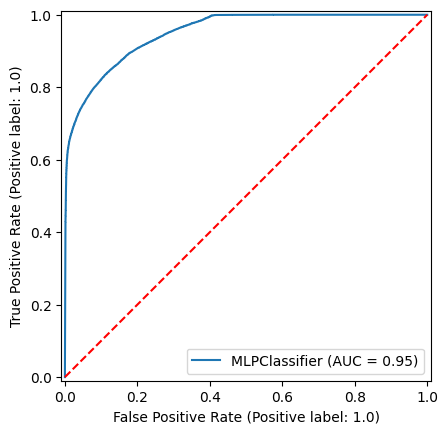

In [19]:
pg.gerar_roc_auc(modelo_campeao, X_teste, y_teste)

##### 7.1.4. Curva Precision-Recall
---

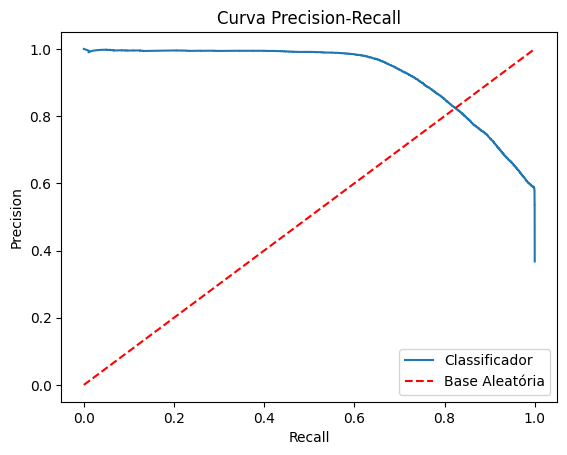

In [20]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_1)

In [21]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_1, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4606
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 66.01% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9325
      Recall real obtido: 68.31% (Ataques detectados)
      Precision real obtida: 95.00% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.7854
      Recall neste ponto: 79.91% (Ataques detectados)
      Precision neste ponto: 85.19% (Acerto dos alertas)


#### 7.2. Limiar Equilibrado
---

##### 7.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [22]:
_, limiar_modelo_campeao, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_1)
print(limiar_modelo_campeao)

0.7853987926684818


In [23]:
y_predicao_probabilistica_equilibrada_1 = (y_predicao_probabilistica_1 > limiar_modelo_campeao).astype(int)

<Axes: >

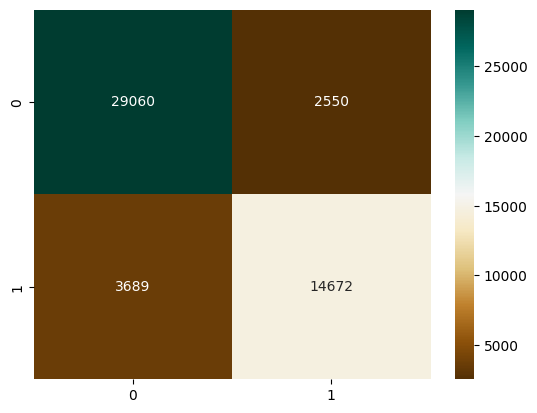

In [24]:
matriz_confusao_equilibrada_1 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_1)
sns.heatmap(matriz_confusao_equilibrada_1, annot=True, fmt='d', cmap='BrBG')

##### 7.2.2. Relatório de Classificação
---

In [25]:
relatorio_classificacao_equilibrado_1 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_1)
print(relatorio_classificacao_equilibrado_1)

              precision    recall  f1-score   support

         0.0       0.89      0.92      0.90     31610
         1.0       0.85      0.80      0.82     18361

    accuracy                           0.88     49971
   macro avg       0.87      0.86      0.86     49971
weighted avg       0.87      0.88      0.87     49971



## E) Desenvolvimento dos Modelo de MLPs de Classificação de duas camadas com 20 features (RFE + XGBoost Classifier)
---

### 1. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

#### 1.1. Instanciamento da classe RFE
---

O objetivo é a diminuição da dimensionalidade, e a escolha das 20 features mais relevantes.

In [68]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [145]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=20)

#### 1.2. Aplicação do RFE em X_treino
---

In [146]:
X_treino_reduzido = seletor_rfe.fit_transform(X_treino, y_treino)

In [147]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features:\n{X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features:\n{list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do RFE:
 - Número de features e registros: (96822, 47)
 - Nomes das features:
Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [72]:
type(X_treino_reduzido)

numpy.ndarray

In [73]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,tamanho_janela_tcp_origem,rtt_handshake_tcp,tempo_syn_synack,tempo_synack_ack,tamanho_medio_pacotes_origem,tamanho_medio_pacotes_destino,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,servico_conexao_outros,estado_conexao_CON,estado_conexao_outros
0,-0.329992,-0.154433,-0.034939,-0.002418,-0.4,-0.333333,-0.054359,1.0,-0.009828,-0.016261,-0.004038,-0.547945,-0.274074,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-0.131161,12.130358,-0.044014,0.808271,0.0,2.500000,0.269346,1.0,-0.009828,-0.016261,-0.004038,-0.424658,7.600000,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,-0.285714,3.666471,-0.054756,0.083443,-0.2,0.666667,2.568450,1.0,0.845333,0.898078,0.820533,-0.506849,5.511111,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.175439,0.021139,-0.052917,-0.010829,-0.2,0.166667,1.570283,1.0,-0.009828,-0.016261,-0.004038,-0.424658,-0.118519,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.214703,-0.126248,-0.043752,-0.009800,0.0,-0.166667,0.241995,1.0,0.971310,1.042226,0.931617,-0.410959,-0.259259,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [74]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.42606516290726815 a 5415.2819548872185

 - Magnitude: 5415.708020050126


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 9427.744951992034

 - Magnitude: 9427.802183623115


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 960.2

 - Magnitude: 960.6


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 913.6666666666666

 - Magnitude: 914.0


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 1065.6872198364367

 - Magnitude: 1066.0485584896207


Feature TAMANHO_JANELA_TCP_ORIGEM:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature RTT_HANDSHAKE_TCP:

 - Amplitude: de -0.009828122445103204 a 19.24055182089483

 - Magnitu

#### 1.3. Aplicação do RFE em X_teste
---

In [75]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [76]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [77]:
type(X_teste_reduzido)

numpy.ndarray

In [78]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,tamanho_janela_tcp_origem,rtt_handshake_tcp,tempo_syn_synack,tempo_synack_ack,tamanho_medio_pacotes_origem,tamanho_medio_pacotes_destino,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,servico_conexao_outros,estado_conexao_CON,estado_conexao_outros
0,-0.230576,-0.204932,283.916144,-0.016329,-0.4,-0.333333,-0.361200,0.0,-0.009828,-0.016261,-0.004038,2.260274,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.298246,-0.204932,1387.032509,-0.016329,-0.4,-0.333333,-0.361238,0.0,-0.009828,-0.016261,-0.004038,10.931507,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,0.008354,-0.204932,1345.152161,-0.016329,-0.4,-0.333333,-0.361275,0.0,-0.009828,-0.016261,-0.004038,6.178082,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,-0.061821,-0.204932,944.612285,-0.016329,-0.4,-0.333333,-0.361263,0.0,-0.009828,-0.016261,-0.004038,5.027397,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,0.450292,-0.204932,1338.854364,-0.016329,-0.4,-0.333333,-0.361212,0.0,-0.009828,-0.016261,-0.004038,13.424658,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0


In [79]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.4277360066833751 a 5996.126148705096

 - Magnitude: 5996.55388471178


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 8294.141531483323

 - Magnitude: 8294.198763114404


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 1063.4

 - Magnitude: 1063.8000000000002


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 917.5

 - Magnitude: 917.8333333333334


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 757.8754070510212

 - Magnitude: 758.2367457042053


Feature TAMANHO_JANELA_TCP_ORIGEM:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature RTT_HANDSHAKE_TCP:

 - Amplitude: de -0.009828122445103204 a 29.195324055790017

 

### 2. Aplicação do PredefinedSplit usando X_treino_reduzido_df
---

In [80]:
limite = int(len(X_treino_reduzido_df) * 0.8)

indices_validacao = np.zeros(X_treino_reduzido.shape[0])
indices_validacao[:limite] = -1  # Treino
indices_validacao[limite:] = 0   # Validação

pds_rfe = PredefinedSplit(test_fold=indices_validacao)

### 3. Criação do modelo base RFE
---

In [81]:

mlp_base_rfe = MLPClassifier(
    max_iter=2000, tol=0.0001, learning_rate_init=0.001, 
    learning_rate='adaptive', alpha=0.001, n_iter_no_change=15, 
    solver="adam", activation='relu', random_state=42
)

### 4. Definição dos parâmetros e instanciação da classe GridSearchCV 
---

In [82]:
parametros = {'hidden_layer_sizes': [(64, 32), (32, 64)]}

In [83]:
# Trocamos cv=5 por cv=pds. Agora ele vai rodar APENAS 1 VEZ cada arquitetura!
grid_search_rfe = GridSearchCV(estimator=mlp_base_rfe, param_grid=parametros, cv=pds_rfe, n_jobs=4, verbose=2)

### 5. Treino dos modelos com GridSearchCV 
---

In [84]:
pm.imprimir_desempenho(grid_search_rfe.fit, X_treino_reduzido_df, y_treino)

Fitting 1 folds for each of 2 candidates, totalling 2 fits

RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 11:37:52

    1. TEMPO: 776.7483s (12.95 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 15.59 MB
        - Diferença líquida de RAM no processo: 3.41 MB
        - Total RAM alocada para o processo: 246.65 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 22.6%

  Execução concluída em: 29/05/2026 11:50:49



GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0], shape=(96822,))),
             estimator=MLPClassifier(alpha=0.001, learning_rate='adaptive',
                                     max_iter=2000, n_iter_no_change=15,
                                     random_state=42),
             n_jobs=4, param_grid={'hidden_layer_sizes': [(64, 32), (32, 64)]},
             verbose=2)

### 6. Resultado e escolha do modelo campeão
---

In [85]:
print("\nResultado:")
print(f" - Melhor arquitetura encontrada: {grid_search_rfe.best_params_['hidden_layer_sizes']}")
print(f" - Acurácia na validação fixa: {grid_search_rfe.best_score_:.4f}")


Resultado:
 - Melhor arquitetura encontrada: (32, 64)
 - Acurácia na validação fixa: 0.9100


In [86]:
modelo_campeao_rfe = grid_search_rfe.best_estimator_

### 7. Realização das Predições de Teste
---

#### 7.1. Predição Probababilística
---

In [87]:
y_predicao_probabilistica_2 = pm.imprimir_desempenho(modelo_campeao_rfe.predict_proba, X_teste_reduzido_df)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 11:50:49

    1. TEMPO: 0.2554s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 36.60 MB
        - Diferença líquida de RAM no processo: 12.32 MB
        - Total RAM alocada para o processo: 259.71 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 51.8%

  Execução concluída em: 29/05/2026 11:50:49



#### 7.2. Predição Binária
---

In [88]:
y_predicao_binaria_2 = pm.imprimir_desempenho(modelo_campeao_rfe.predict, X_teste_reduzido_df)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 11:50:49

    1. TEMPO: 0.2539s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 36.60 MB
        - Diferença líquida de RAM no processo: 0.40 MB
        - Total RAM alocada para o processo: 260.13 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 41.3%

  Execução concluída em: 29/05/2026 11:50:49



### 8. Desempenho do modelo
---

#### 8.1. Limiar Padrão (0.5)
---

##### 8.1.1. Matriz de Confusão
---

<Axes: >

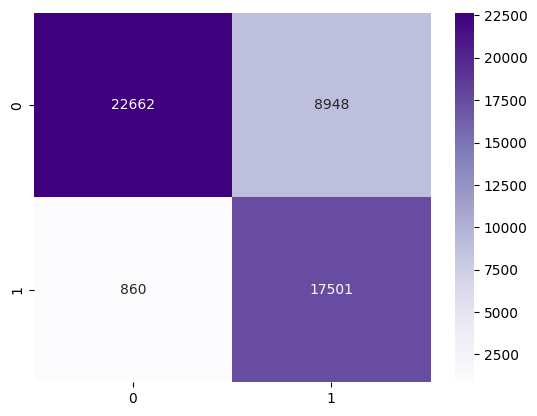

In [89]:
matriz_confusao_2 = confusion_matrix(y_teste, y_predicao_binaria_2)
sns.heatmap(matriz_confusao_2, annot=True, fmt='d', cmap='Purples')

##### 8.1.2. Relatório de Classificação
---

In [90]:
relatorio_classificacao_2 = classification_report(y_teste, y_predicao_binaria_2)
print(relatorio_classificacao_2)

              precision    recall  f1-score   support

         0.0       0.96      0.72      0.82     31610
         1.0       0.66      0.95      0.78     18361

    accuracy                           0.80     49971
   macro avg       0.81      0.84      0.80     49971
weighted avg       0.85      0.80      0.81     49971



##### 8.1.3. Curva ROC-AUC
---

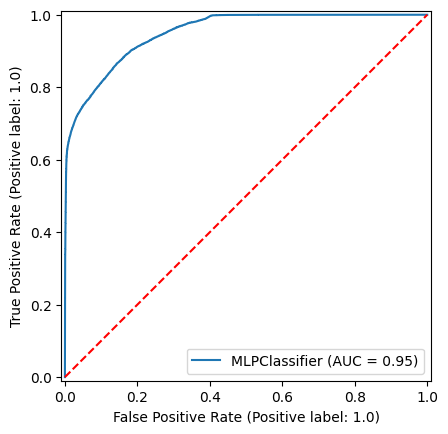

In [110]:
pg.gerar_roc_auc(modelo_campeao_rfe, X_teste_reduzido_df, y_teste)

##### 8.1.4. Curva Precision-Recall
---

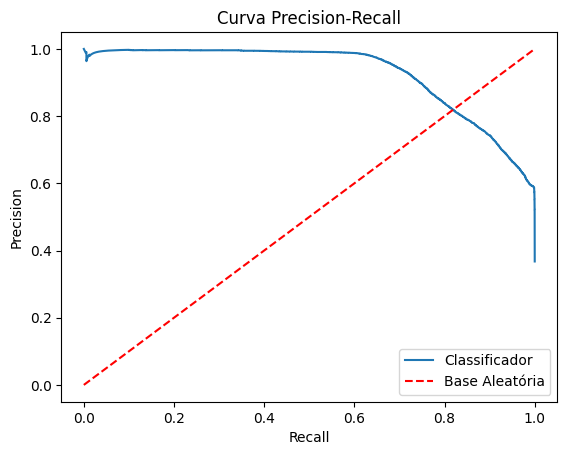

In [92]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_2)

In [93]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_2, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.5103
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 66.48% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 0.9046
      Recall real obtido: 68.90% (Ataques detectados)
      Precision real obtida: 95.01% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.6982
      Recall neste ponto: 85.71% (Ataques detectados)
      Precision neste ponto: 78.53% (Acerto dos alertas)


#### 8.2. Limiar Equilibrado
---

##### 8.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [102]:
_, limiar_modelo_campeao_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_2)
print(limiar_modelo_campeao_rfe)

0.6982408896153841


In [103]:
y_predicao_probabilistica_equilibrada_2 = (y_predicao_probabilistica_2 > limiar_modelo_campeao_rfe).astype(int)

<Axes: >

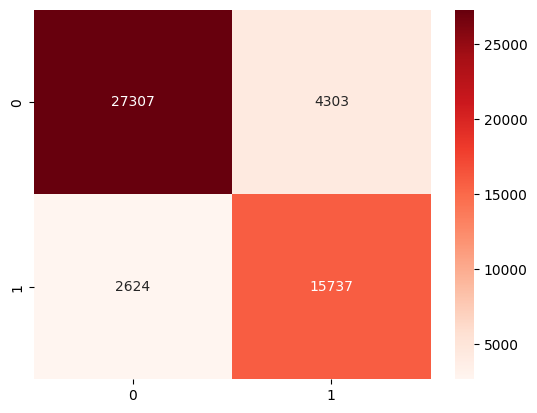

In [104]:
matriz_confusao_equilibrada_2 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_2)
sns.heatmap(matriz_confusao_equilibrada_2, annot=True, fmt='d', cmap='Reds')

##### 8.2.2. Relatório de Classificação
---

In [105]:
relatorio_classificacao_equilibrado_2 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_2)
print(relatorio_classificacao_equilibrado_2)

              precision    recall  f1-score   support

         0.0       0.91      0.86      0.89     31610
         1.0       0.79      0.86      0.82     18361

    accuracy                           0.86     49971
   macro avg       0.85      0.86      0.85     49971
weighted avg       0.87      0.86      0.86     49971



## F) Comparando os Modelos Campeões
---

### 1. Desempenho dos modelos
---

In [109]:
print('\nComparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:\n')

print('\n1. MODELO CAMPEÃO SEM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_1)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_1)

print('\n\n2. MODELO CAMPEÃO COM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_2)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_2)



Comparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:


1. MODELO CAMPEÃO SEM RFE:

 - Padrão:

O total de predições de teste foi 49971.


 -> Classe 0:
    - Verdadeiro Negativo (TN): há 23471 casos, o que representa, aproximadamente, 46.97% do total de predições de teste.
    - Falso Negativo (FN): há 1170 casos, o que representa, aproximadamente, 2.34% do total de predições de teste.

 -> Classe 1:
   - Verdadeiro Positivo (TP): há 17191 casos, o que representa, aproximadamente, 34.40% do total de predições de teste.
   - Falso Positivo (FP): há 8139 casos, o que representa, aproximadamente, 16.29% do total de predições de teste.


 -> Resultados Gerais:
    - A Acurácia total do modelo se dá por: (tp + tn) / total. Seu valor é 0.8137.
    - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a 40662, de um total de 49971. Corresponde a, aproximadamente, 81.37% das predições.
    - A quantidade de vezes que o modelo

### 2. Diferenças entre os desempenhos
---

In [ ]:
# Modelo campeão sem RFE
dados_modelo_1 = pm.extracao_desempenho_modelo(matriz_confusao_1)
dados_modelo_equilibrado_1 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_1)

# Modelo campeão com RFE
dados_modelo_2 = pm.extracao_desempenho_modelo(matriz_confusao_2)
dados_modelo_equilibrado_2 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_2)

# Total de registros
total_registros = dados_modelo_1['tn'] + dados_modelo_1['tp'] + dados_modelo_1['fn'] + dados_modelo_1['fp']

In [ ]:
print('A) As diferenças métricas entre os modelos são:\n')
print('Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).')

print('\n1. Limiar Padrão (0.5):')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_1["tn"]} | Com RFE - {dados_modelo_2["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_2["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_1["tp"]} | Com RFE - {dados_modelo_2["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_2["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_1["fn"]} | Com RFE - {dados_modelo_2["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_2["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_1["fp"]} | Com RFE - {dados_modelo_2["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_2["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_1["accuracy"]} | Com RFE - {dados_modelo_2["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Sem RFE - {dados_modelo_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Sem RFE - {dados_modelo_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Limiar Equilibrado:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_equilibrado_1["tn"]} | Com RFE - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_equilibrado_1["tp"]} | Com RFE - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_equilibrado_1["fn"]} | Com RFE - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_equilibrado_1["fp"]} | Com RFE - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_equilibrado_1["accuracy"]} | Com RFE - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n\nAs diferenças métricas entre os limiares dos modelos são:\n')
print('\nB) Modelo sem RFE:')
print(f'    TN: Padrão - {dados_modelo_1["tn"]} | Equilibrado - {dados_modelo_equilibrado_1["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_1["tp"]} | Equilibrado - {dados_modelo_equilibrado_1["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_1["fn"]} | Equilibrado - {dados_modelo_equilibrado_1["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_1["fp"]} | Equilibrado - {dados_modelo_equilibrado_1["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_1["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_1["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Padrão - {dados_modelo_1["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_1["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_1["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Padrão - {dados_modelo_1["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_1["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_1["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 1):.2f}%')

print('\nC) Modelo com RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_2["tn"]} | Equilibrado - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_2["tp"]} | Equilibrado - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_2["fn"]} | Equilibrado - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_2["fp"]} | Equilibrado - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_2["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Padrão - {dados_modelo_2["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_2["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_2["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Padrão - {dados_modelo_2["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_2["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_2["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

## G) Persisitindo os Modelos
---

### 1. Primeiro modelo - Modelo campeão, sem RFE
---

In [107]:
joblib.dump(modelo_campeao, '../persistencia/modelos_persistentes/mlp/mlp_2c/mlp_2c.pkl')

['../modelos_persistentes/mlp/mlp_2c/mlp_2c.pkl']

### 2. Segundo modelo - Modelo campeão, com RFE
---

In [56]:
joblib.dump(modelo_campeao_rfe, '../persistencia/modelos_persistentes/mlp/mlp_2c/mlp_2c_rfe.pkl')

['../modelos_persistentes/mlp/mlp_2c/mlp_2c_rfe.pkl']